# Discretização

Este notebook discretiza o modelo linearizado em espaço de estados, $\dot{\mathbf{x}}(t) = \mathbf{A}\,\mathbf{x}(t) + \mathbf{B}\,\mathbf{u}(t)$, obtendo um modelo no tempo discreto,

$$\mathbf{x}[k+1] = \mathbf{A}_d\,\mathbf{x}[k] + \mathbf{B}_d\,\mathbf{u}[k], \qquad \mathbf{y}[k] = \mathbf{C}\,\mathbf{x}[k]$$

para um período de amostragem $T_s$. A discretização é feita de duas formas, pelo método de **Euler** e pelo **retentor de ordem zero (ZOH)**, e as respostas dos dois modelos discretos são comparadas entre si e com a do modelo contínuo.


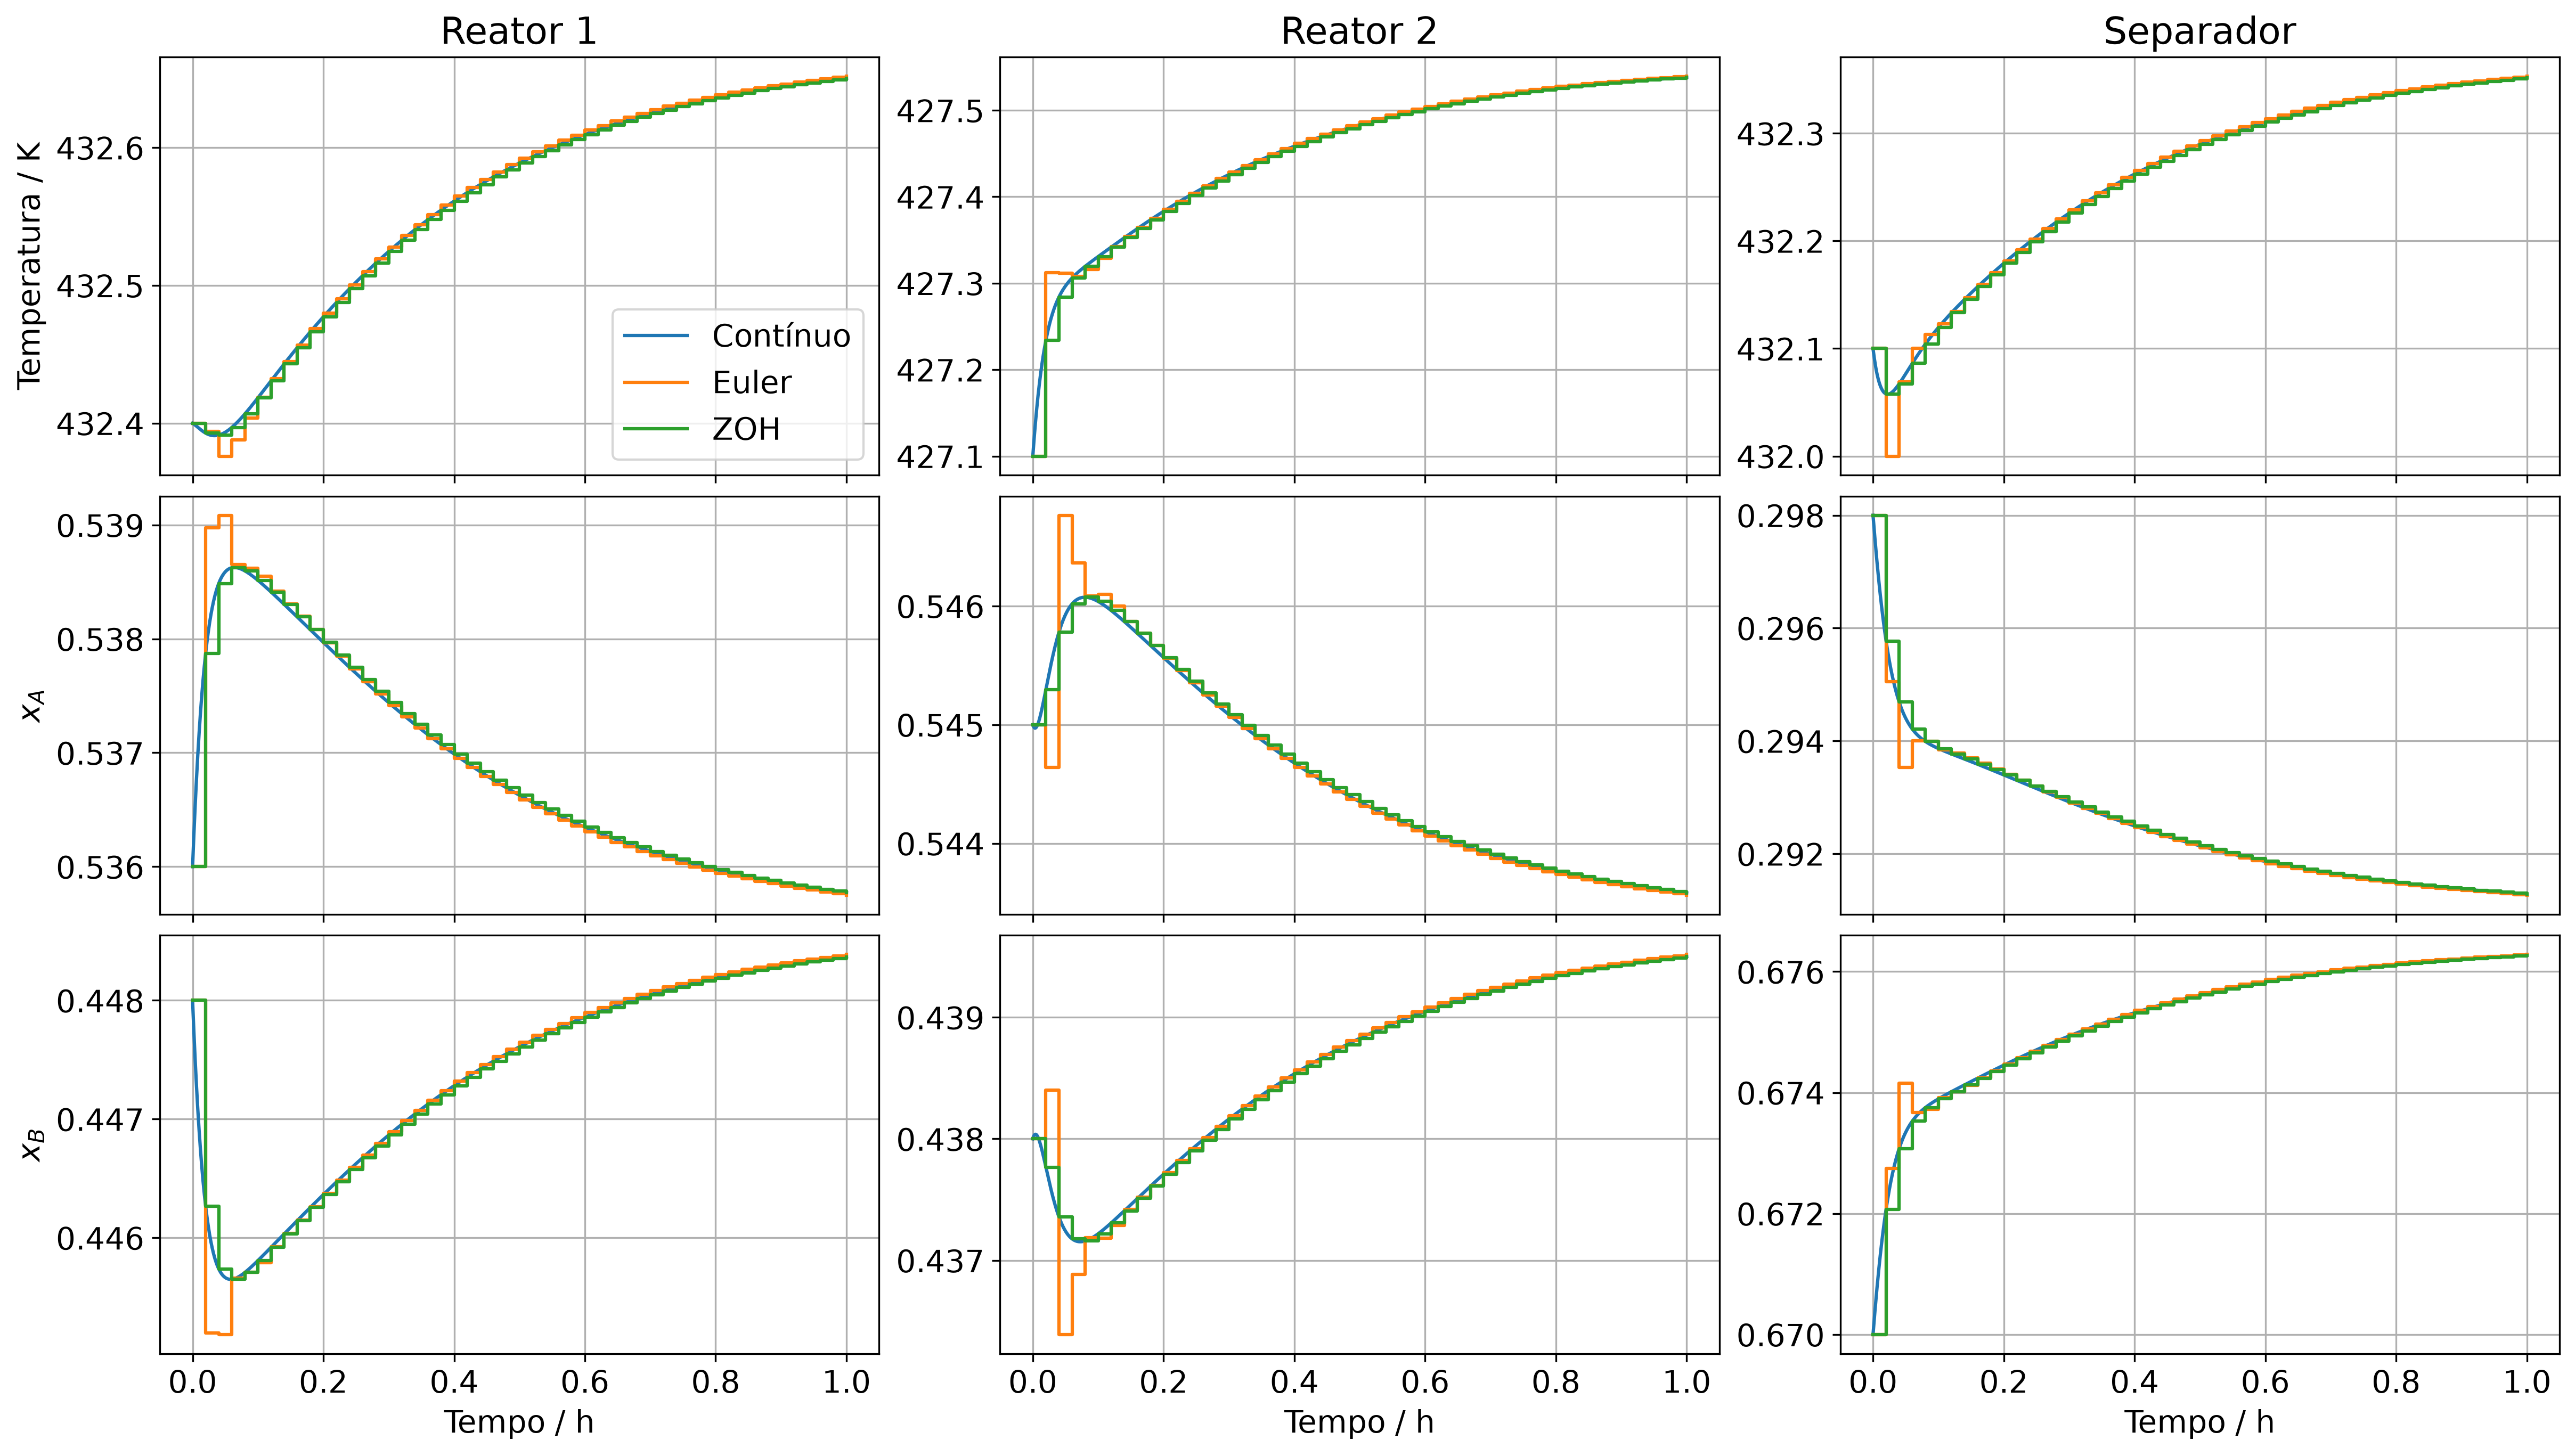

In [1]:
import hickle as hkl
import numpy as np
from scipy import signal

from lib.parameters import y0
from lib.plots import plot_and_show, plt
from lib.utils import input_names, output_units

Ts = 0.02  # período de amostragem / h
T_final = 1.0  # horizonte de simulação / h
j = 2  # entrada com degrau unitário: 0 = Ff1, 1 = Ff2, 2 = FR

A = np.array(hkl.load("../outputs/A.hkl"), dtype=float)
B = np.array(hkl.load("../outputs/B.hkl"), dtype=float)
C = np.array(hkl.load("../outputs/C.hkl"), dtype=float)
D = np.zeros((C.shape[0], B.shape[1]))
x_ss = np.asarray(y0, dtype=float)

# Discretização: Euler e ZOH
metodos = {"Euler": "euler", "ZOH": "zoh"}
sistemas_d = {
    nome: signal.cont2discrete((A, B, C, D), Ts, method=m)[:4]  # type: ignore
    for nome, m in metodos.items()
}

# Degrau unitário na entrada j
u = np.zeros(B.shape[1])
u[j] = 1.0

# Simulação contínua
tc = np.linspace(0, T_final, 1000)
_, yc, _ = signal.lsim((A, B, C, D), U=np.tile(u, (len(tc), 1)), T=tc)
yc = yc.T + x_ss[:, None]

# Simulação dos sistemas discretos, nos instantes de amostragem
td = np.arange(0, T_final + Ts / 2, Ts)


def simular(Ad, Bd, Cd, Dd, n):
    x = np.zeros((Ad.shape[0], n))
    y = np.zeros((Cd.shape[0], n))
    for k in range(n):
        y[:, k] = Cd @ x[:, k] + Dd @ u
        if k + 1 < n:
            x[:, k + 1] = Ad @ x[:, k] + Bd @ u
    return y


yd = {nome: simular(*sd, len(td)) + x_ss[:, None] for nome, sd in sistemas_d.items()}  # type: ignore

# Gráficos: linhas = temperatura, xA, xB; colunas = reator 1, reator 2, separador
linhas = [
    (f"Temperatura / {output_units[0]}", [0, 1, 2]),
    ("$x_A$", [3, 5, 7]),
    ("$x_B$", [4, 6, 8]),
]
titulos = ["Reator 1", "Reator 2", "Separador"]

fig, axs = plt.subplots(3, 3, figsize=(16, 9), sharex=True, constrained_layout=True)

for r, (ylabel, estados) in enumerate(linhas):
    for c, e in enumerate(estados):
        ax = axs[r, c]
        ax.plot(tc, yc[e], "C0", label="Contínuo")
        for n, (nome, y) in enumerate(yd.items(), start=1):
            ax.step(td, y[e], where="post", color=f"C{n}", label=nome)

        if r == 0:
            ax.set_title(titulos[c])
        if c == 0:
            ax.set_ylabel(ylabel)
        if r == 2:
            ax.set_xlabel("Tempo / h")
        ax.grid(True)

axs[0, 0].legend()
plot_and_show(f"discretizacao-{input_names[j]}")


Com $T_s = 0{,}02$ h, os dois modelos discretos acompanham o contínuo e convergem para o mesmo valor final. A diferença está só no início da dinâmica: o Euler ultrapassa a curva contínua e oscila, enquanto o ZOH é exato nos instantes de amostragem. Depois do transitório, os três são praticamente indistinguíveis.
